Name: Divyadharshini S
Roll no: 24BAD022
11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

Dataset Information
Training data shape: (60000, 28, 28)
Testing data shape: (10000, 28, 28)
Data type: uint8
Number of training samples: 60000
Number of testing samples: 10000
Minimum pixel value: 0
Maximum pixel value: 255


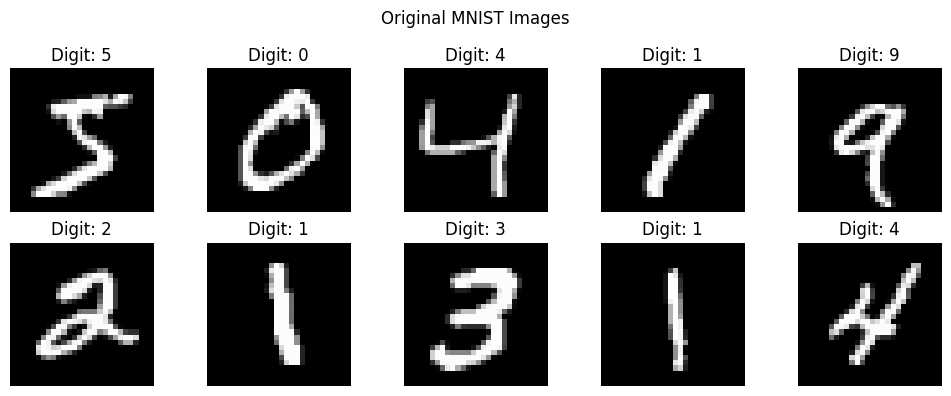


Prepared Dataset
Training shape: (60000, 28, 28, 1)
Batch size: 128
Normalized minimum: -1.0
Normalized maximum: 1.0


In [1]:
print("Name: Divyadharshini S\nRoll no: 24BAD022")
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.datasets import mnist
(x_train, y_train), (x_test, y_test) = mnist.load_data()
print("\nDataset Information")
print("Training data shape:", x_train.shape)
print("Testing data shape:", x_test.shape)
print("Data type:", x_train.dtype)
print("Number of training samples:", len(x_train))
print("Number of testing samples:", len(x_test))

print("Minimum pixel value:", x_train.min())
print("Maximum pixel value:", x_train.max())

plt.figure(figsize=(10, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap="gray")
    plt.title(f"Digit: {y_train[i]}")
    plt.axis("off")

plt.suptitle("Original MNIST Images")
plt.tight_layout()
plt.show()

x_train = x_train.astype("float32")
x_train = (x_train - 127.5) / 127.5
x_train = x_train.reshape(-1, 28, 28, 1)
BATCH_SIZE = 128
train_dataset = tf.data.Dataset.from_tensor_slices(x_train)
train_dataset = (
    train_dataset
    .shuffle(60000)
    .batch(BATCH_SIZE, drop_remainder=True)
    .prefetch(tf.data.AUTOTUNE)
)

print("\nPrepared Dataset")
print("Training shape:", x_train.shape)
print("Batch size:", BATCH_SIZE)
print("Normalized minimum:", x_train.min())
print("Normalized maximum:", x_train.max())

Name: Divyadharshini S
Roll no: 24BAD022
GENERATOR MODEL SUMMARY


Model: "Generator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │        12,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 512)            │       131,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 784)            │       402,192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 28, 28, 1)      │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 579,728 (2.21 MB)

 Trainable params: 579,728 (2.21 MB)

 Non-trainable params: 0 (0.00 B)

... (3 outputs left out)

 Total params: 533,505 (2.04 MB)

 Trainable params: 533,505 (2.04 MB)

 Non-trainable params: 0 (0.00 B)


Generated image shape: (1, 28, 28, 1)


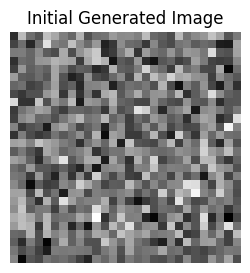

In [2]:
print("Name: Divyadharshini S\nRoll no: 24BAD022")

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, LeakyReLU, Reshape, Flatten, Input
LATENT_DIM = 100

generator = Sequential([
    Input(shape=(LATENT_DIM,)),
    Dense(128),
    LeakyReLU(negative_slope=0.2),
    Dense(256),
    LeakyReLU(negative_slope=0.2),
    Dense(512),
    LeakyReLU(negative_slope=0.2),
    Dense(784, activation="tanh"),
    Reshape((28, 28, 1))
], name="Generator")

discriminator = Sequential([
    Input(shape=(28, 28, 1)),
    Flatten(),
    Dense(512),
    LeakyReLU(negative_slope=0.2),
    Dense(256),
    LeakyReLU(negative_slope=0.2),
    Dense(1)
], name="Discriminator")

discriminator.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0002),
    loss=tf.keras.losses.BinaryCrossentropy(from_logits=True),
    metrics=["accuracy"]
)

print("GENERATOR MODEL SUMMARY")
generator.summary()

print("\nDISCRIMINATOR MODEL SUMMARY")
discriminator.summary()

noise = tf.random.normal([1, LATENT_DIM])
generated_image = generator(noise, training=False)
print("\nGenerated image shape:", generated_image.shape)

plt.figure(figsize=(3, 3))
plt.imshow(generated_image[0, :, :, 0], cmap="gray")
plt.title("Initial Generated Image")
plt.axis("off")
plt.show()

Name: Divyadharshini S
Roll no: 24BAD022
Epoch 1/20 | Generator Loss: 1.1877 | Discriminator Loss: 1.0024
Epoch 2/20 | Generator Loss: 1.6079 | Discriminator Loss: 0.8743
Epoch 3/20 | Generator Loss: 1.5480 | Discriminator Loss: 0.9041
Epoch 4/20 | Generator Loss: 1.6914 | Discriminator Loss: 0.8379
Epoch 5/20 | Generator Loss: 1.7980 | Discriminator Loss: 0.8253


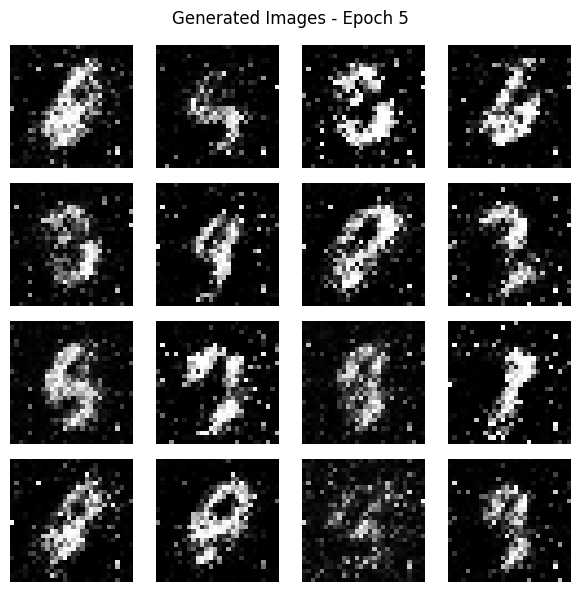

Epoch 6/20 | Generator Loss: 1.8013 | Discriminator Loss: 0.7596
Epoch 7/20 | Generator Loss: 1.7855 | Discriminator Loss: 0.7750
Epoch 8/20 | Generator Loss: 1.9293 | Discriminator Loss: 0.7339
Epoch 9/20 | Generator Loss: 1.8649 | Discriminator Loss: 0.7371
Epoch 10/20 | Generator Loss: 1.7998 | Discriminator Loss: 0.7681


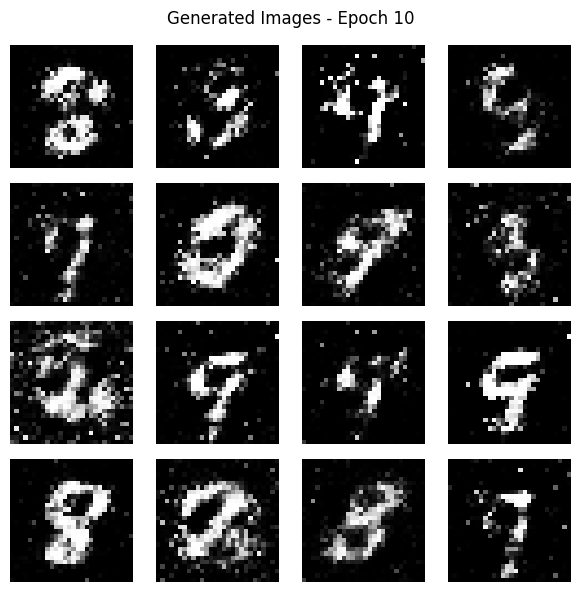

Epoch 11/20 | Generator Loss: 1.7049 | Discriminator Loss: 0.8207
Epoch 12/20 | Generator Loss: 1.4517 | Discriminator Loss: 0.9404
Epoch 13/20 | Generator Loss: 1.3069 | Discriminator Loss: 0.9891
Epoch 14/20 | Generator Loss: 1.3516 | Discriminator Loss: 0.9676
Epoch 15/20 | Generator Loss: 1.2606 | Discriminator Loss: 1.0166


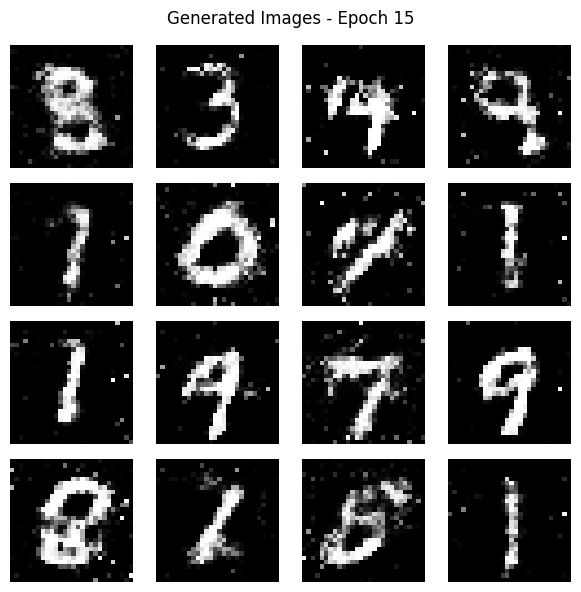

Epoch 16/20 | Generator Loss: 1.2370 | Discriminator Loss: 1.0385
Epoch 17/20 | Generator Loss: 1.2172 | Discriminator Loss: 1.0574
Epoch 18/20 | Generator Loss: 1.2198 | Discriminator Loss: 1.0552
Epoch 19/20 | Generator Loss: 1.1982 | Discriminator Loss: 1.0601
Epoch 20/20 | Generator Loss: 1.1980 | Discriminator Loss: 1.0661


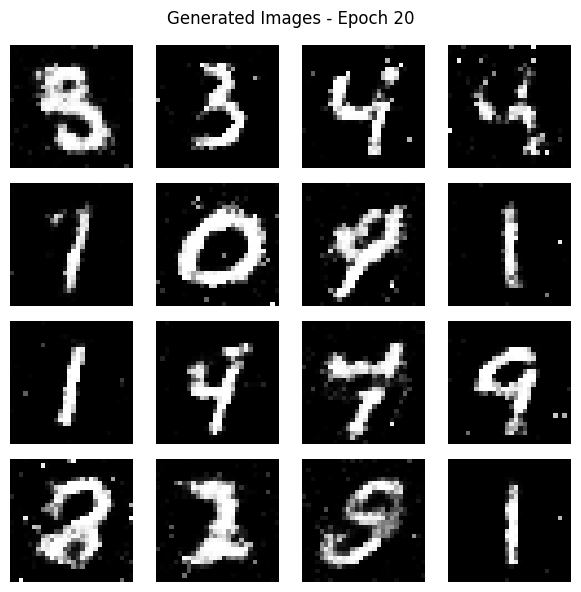

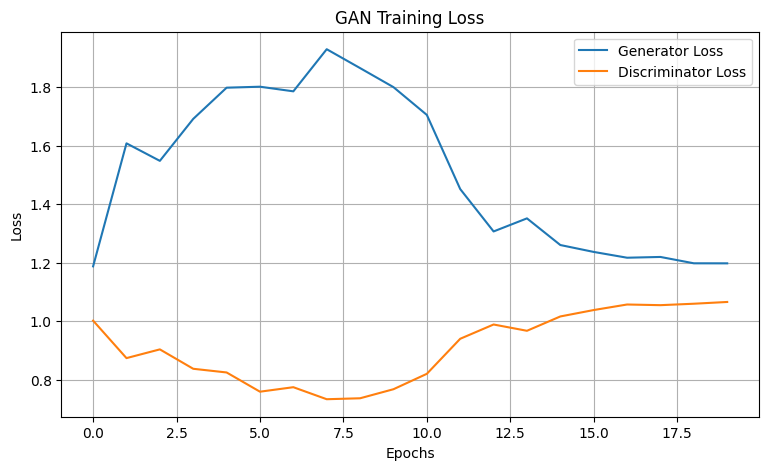

In [3]:
print("Name: Divyadharshini S\nRoll no: 24BAD022")

cross_entropy = tf.keras.losses.BinaryCrossentropy(
    from_logits=True
)
generator_optimizer = tf.keras.optimizers.Adam(
    learning_rate=0.0002,
    beta_1=0.5
)
discriminator_optimizer = tf.keras.optimizers.Adam(
    learning_rate=0.0002,
    beta_1=0.5
)

def generator_loss(fake_output):
    return cross_entropy(
        tf.ones_like(fake_output),
        fake_output
    )
def discriminator_loss(real_output, fake_output):
    real_loss = cross_entropy(
        tf.ones_like(real_output),
        real_output
    )
    fake_loss = cross_entropy(
        tf.zeros_like(fake_output),
        fake_output
    )
    return real_loss + fake_loss
fixed_noise = tf.random.normal([16, LATENT_DIM])
gen_losses = []
disc_losses = []
@tf.function
def train_step(real_images):
    noise = tf.random.normal(
        [BATCH_SIZE, LATENT_DIM]
    )
    with tf.GradientTape() as disc_tape:
        fake_images = generator(noise, training=True)
        real_output = discriminator(
            real_images,
            training=True
        )
        fake_output = discriminator(
            tf.stop_gradient(fake_images),
            training=True
        )
        d_loss = discriminator_loss(
            real_output,
            fake_output
        )
    disc_gradients = disc_tape.gradient(
        d_loss,
        discriminator.trainable_variables
    )
    discriminator_optimizer.apply_gradients(
        zip(
            disc_gradients,
            discriminator.trainable_variables
        )
    )
    noise = tf.random.normal(
        [BATCH_SIZE, LATENT_DIM]
    )
    with tf.GradientTape() as gen_tape:
        generated_images = generator(
            noise,
            training=True
        )
        fake_output = discriminator(
            generated_images,
            training=False
        )
        g_loss = generator_loss(fake_output)
    gen_gradients = gen_tape.gradient(
        g_loss,
        generator.trainable_variables
    )
    generator_optimizer.apply_gradients(
        zip(
            gen_gradients,
            generator.trainable_variables
        )
    )
    return g_loss, d_loss
EPOCHS = 20
for epoch in range(EPOCHS):
    total_gen_loss = 0
    total_disc_loss = 0
    batches = 0
    for image_batch in train_dataset:
        g_loss, d_loss = train_step(image_batch)
        total_gen_loss += g_loss
        total_disc_loss += d_loss
        batches += 1
    avg_gen_loss = total_gen_loss / batches
    avg_disc_loss = total_disc_loss / batches
    gen_losses.append(float(avg_gen_loss.numpy()))
    disc_losses.append(float(avg_disc_loss.numpy()))
    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"Generator Loss: {avg_gen_loss:.4f} | "
        f"Discriminator Loss: {avg_disc_loss:.4f}"
    )

    if (epoch + 1) % 5 == 0:
        predictions = generator(
            fixed_noise,
            training=False
        )
        plt.figure(figsize=(6, 6))
        for i in range(16):
            plt.subplot(4, 4, i + 1)
            plt.imshow(
                predictions[i, :, :, 0],
                cmap="gray"
            )
            plt.axis("off")
        plt.suptitle(
            f"Generated Images - Epoch {epoch + 1}"
        )
        plt.tight_layout()
        plt.show()

plt.figure(figsize=(9, 5))
plt.plot(
    gen_losses,
    label="Generator Loss"
)
plt.plot(
    disc_losses,
    label="Discriminator Loss"
)
plt.title("GAN Training Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()


Name: Divyadharshini S
Roll no: 24BAD022
Synthetic Images Generated Successfully
Generated image shape: (25, 28, 28, 1)


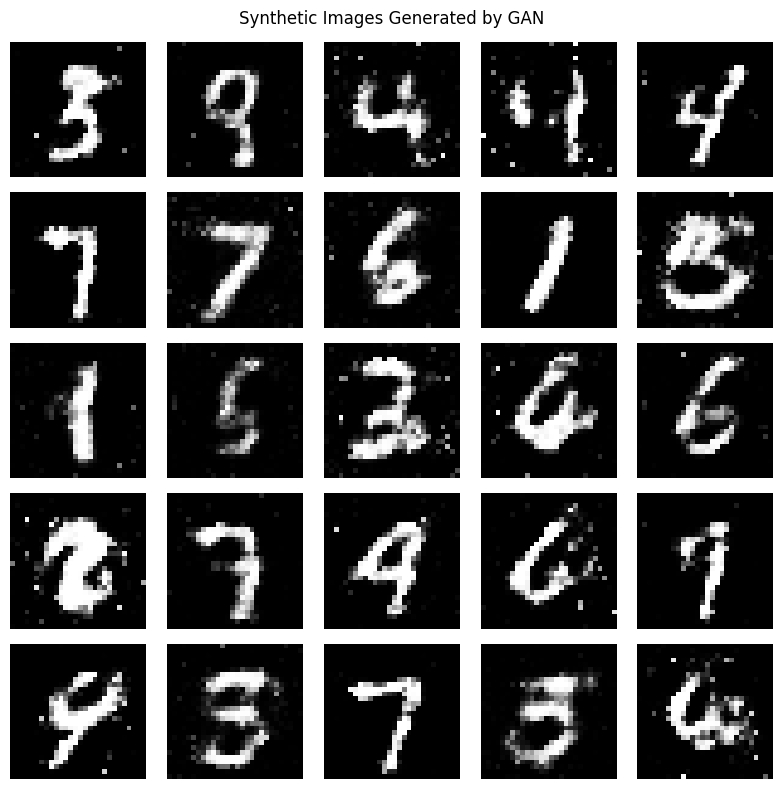

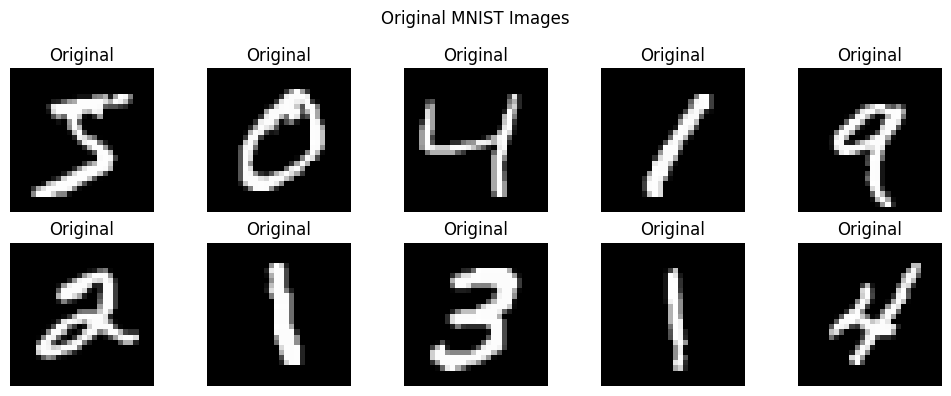

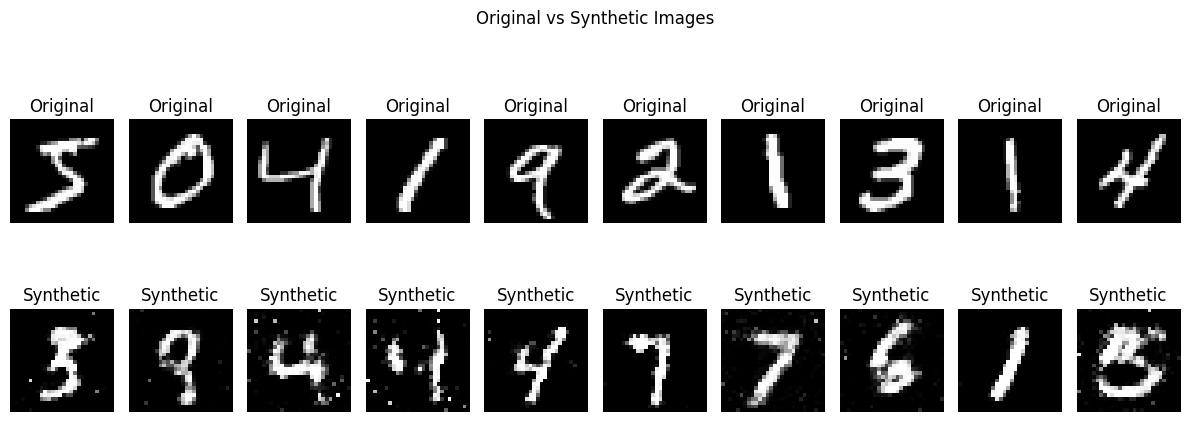

In [4]:
print("Name: Divyadharshini S\nRoll no: 24BAD022")

new_noise = tf.random.normal([25, LATENT_DIM])
synthetic_images = generator(
    new_noise,
    training=False
)
print("Synthetic Images Generated Successfully")
print("Generated image shape:", synthetic_images.shape)

plt.figure(figsize=(8, 8))
for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.imshow(
        synthetic_images[i, :, :, 0],
        cmap="gray"
    )
    plt.axis("off")
plt.suptitle("Synthetic Images Generated by GAN")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(
        x_train[i, :, :, 0],
        cmap="gray"
    )
    plt.title("Original")
    plt.axis("off")

plt.suptitle("Original MNIST Images")
plt.tight_layout()
plt.show()
plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 10, i + 1)
    plt.imshow(x_train[i, :, :, 0],cmap="gray")
    plt.title("Original")
    plt.axis("off")
    plt.subplot(2, 10, i + 11)
    plt.imshow(
        synthetic_images[i, :, :, 0],
        cmap="gray"
    )
    plt.title("Synthetic")
    plt.axis("off")

plt.suptitle("Original vs Synthetic Images")
plt.tight_layout()
plt.show()

generator.save("mnist_gan_generator.keras")
discriminator.save("mnist_gan_discriminator.keras")